# c6 · Step 6: Optimisation tuning

Input from c5, model still the c4 initial model. Settings are tuned in order of how much they usually matter,
**one at a time**; each section starts from the winners of the previous ones. 3 seeds per option. Rule
(`compare`/`pick`): the option with the highest mean val balanced accuracy wins, whatever its size or cost.

| # | Setting | Options |
|---|---|---|
| 1 | learning rate (Adam) | 1e-4, 3e-4, **1e-3**, 3e-3, 1e-2 (extended if the best is at the edge) |
| 2 | optimiser | **Adam** vs SGD + Nesterov momentum (own LR sweep: 3e-3, 1e-2, 3e-2, 1e-1) |
| 3 | batch size | 32, **64**, 128 |
| 4 | LR schedule | **none**, cosine annealing, step decay (÷10 at 50 % and 75 %), reduce-on-plateau |
| 5 | loss / imbalance | **cross-entropy**, class-weighted CE, CE + weighted sampler, label smoothing 0.1, focal (γ=2) |

Bold = the current default, i.e. the baseline of each comparison.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib.train import Config, run
from lib.report import run_seeds, compare, pick, sigma_seed, log_progress, curve_test
from lib.data import ARTIFACTS
from lib.report import protocol; proto = protocol()   # c4 protocol with the raised epoch cap
INPUT = json.loads((ARTIFACTS / "input.json").read_text())
CUR = replace(Config(exp="c6", name="x", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]), **INPUT)
BASE_RUNS = run_seeds(replace(CUR, exp="c4" if CUR.epochs == 60 else "c5", name="seed" if CUR.epochs == 60 else "crop")) if INPUT == dict(mode="gray", resize="crop", size=128, normalize="global") \
    else run_seeds(replace(CUR, exp="c5", name="input_choice"))
print(INPUT, proto)

{'mode': 'gray', 'resize': 'crop', 'size': 128, 'normalize': 'per_image'} {'monitor': 'val_bal_acc', 'patience': 20, 'epochs': 60}


## 0. Device check
Part of this notebook may run on a different machine than c4/c5 (Mac M1 / MPS vs desktop RTX 2080 Ti / CUDA).
Same seed and config do not give identical numbers on different devices, so if the current device differs from
the one the baseline runs were made on, the c4 baseline is retrained here with the same 3 seeds. If the device
offset is well inside the seed noise, runs from both devices can be compared with the usual rule.

In [2]:
from lib.train import DEVICE
base_dev = {r["device"] for r in BASE_RUNS}
if {str(DEVICE)} != base_dev:
    dev_runs = run_seeds(replace(CUR, name=f"devcheck_{DEVICE.type}"))
    t = compare({f"baseline on {'/'.join(base_dev)}": BASE_RUNS, f"baseline on {DEVICE}": dev_runs},
                f"baseline on {'/'.join(base_dev)}", "same config, different device"); display(t)
else:
    print(f"all baseline runs were made on {DEVICE}: nothing to check")

all baseline runs were made on cuda: nothing to check


## 1. Learning rate

**Decision rule for ordered numeric settings.** Take the value with the highest mean. The trend and peak fits
(val balanced accuracy of every run regressed on log10(LR), line and parabola) are reported to show how strong
the effect is, but they do not gate the choice. If the best value is at the edge of the sweep, extend the sweep
one step (×3 or ×1/3) and repeat, at most twice.

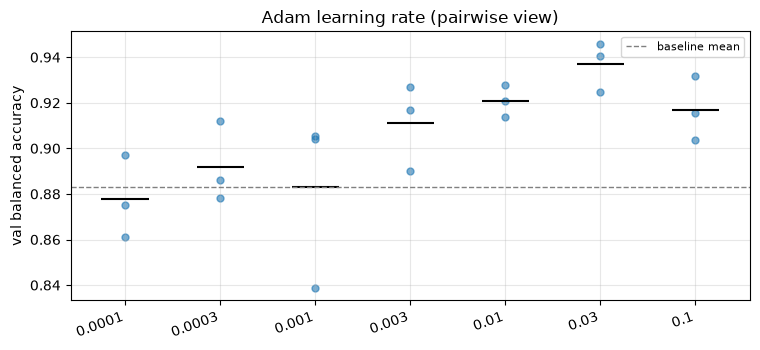

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0.0001,0.8778,0.0181,3.0,-0.0051,0.0505,0.8706,0.9899,0.8820,60.0000,100244.0,0.5347
0.0003,0.8920,0.0178,3.0,0.0092,0.0505,0.8829,0.9875,0.9202,48.3333,100244.0,0.5254
0.001,0.8828,0.0383,3.0,0.0000,0.0505,0.8781,0.9906,0.9028,47.0000,100244.0,0.5598
0.003,0.9112,0.0192,3.0,0.0284,0.0505,0.8967,0.9910,0.9271,45.6667,100244.0,0.5297
0.01,0.9209,0.0070,3.0,0.0381,0.0505,0.9131,0.9935,0.9271,54.6667,100244.0,0.5331
0.03,0.9371,0.0111,3.0,0.0542,0.0505,0.9321,0.9931,0.9479,55.0000,100244.0,0.5352
0.1,0.9170,0.0141,3.0,0.0342,0.0505,0.9100,0.9894,0.9236,57.6667,100244.0,0.5364


{'slope_per_decade': np.float64(0.0175), 'slope_ci': (np.float64(0.008182980619567902), np.float64(0.026773266099207216)), 'p_linear': np.float64(0.0009), 'p_quadratic': np.float64(0.4412), 'has_shape': True, 'best': 0.03, 'best_at_edge': False}


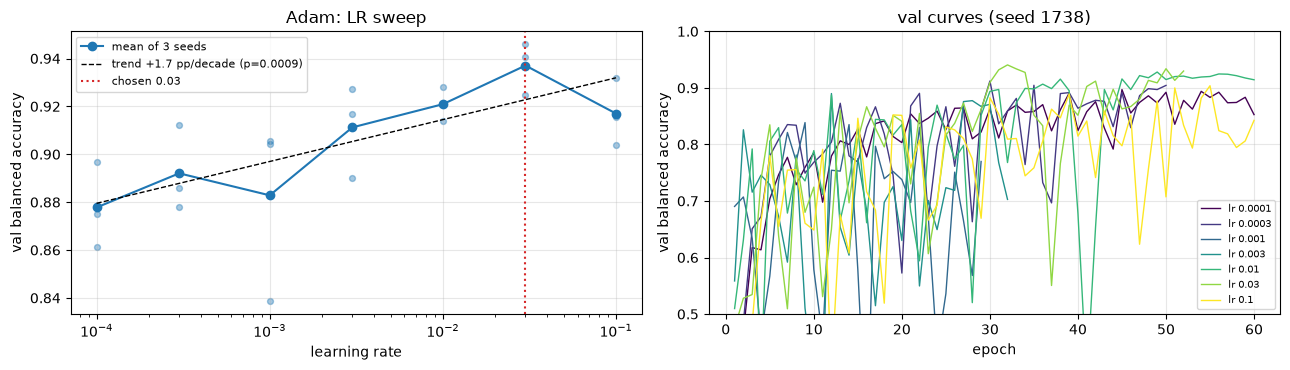

chosen lr: 0.03


In [3]:
def lr_sweep(cfg, lrs, prefix, base_runs=None, base_lr=None, max_ext=2):
    runs = {lr: (base_runs if lr == base_lr else run_seeds(replace(cfg, name=f"{prefix}_lr{lr:g}", lr=lr))) for lr in lrs}
    for _ in range(max_ext):
        ct = curve_test(runs)
        if not ct["best_at_edge"]:
            break
        lo, hi = min(runs), max(runs)
        step = lambda v, up: float(f"{v * (10 / 3 if (f'{v:e}'[0] == '3') == up else 3) ** (1 if up else -1):.1g}")  # 1-3-10 grid
        new = step(hi, True) if ct["best"] == hi else step(lo, False)
        runs[new] = run_seeds(replace(cfg, name=f"{prefix}_lr{new:g}", lr=new))
        runs = dict(sorted(runs.items()))
    return runs, curve_test(runs)

def show_sweep(runs, ct, title, ax):
    xs = sorted(runs); m = [ct["means"][x] for x in xs]
    for x in xs:
        ax.scatter([x] * len(runs[x]), [r["val"]["bal_acc"] for r in runs[x]], color="C0", alpha=0.4, s=18)
    ax.plot(xs, m, "o-", color="C0", label="mean of 3 seeds")
    xx = np.logspace(np.log10(xs[0]), np.log10(xs[-1]), 50)
    ax.plot(xx, np.mean(m) + ct["slope_per_decade"] * (np.log10(xx) - np.mean(np.log10(xs))), "k--", lw=1,
            label=f"trend {ct['slope_per_decade'] * 100:+.1f} pp/decade (p={ct['p_linear']:.1g})")
    ax.axvline(ct["best"], color="C3", ls=":", label=f"chosen {ct['best']:g}")
    ax.set(xscale="log", xlabel="learning rate", ylabel="val balanced accuracy", title=title); ax.grid(alpha=0.3); ax.legend(fontsize=8)

adam_runs, ct_adam = lr_sweep(CUR, [1e-4, 3e-4, 1e-3, 3e-3, 1e-2], "adam", BASE_RUNS, 1e-3)
t = compare({f"{k:g}": v for k, v in adam_runs.items()}, "0.001", "Adam learning rate (pairwise view)"); display(t)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in ct_adam.items() if k != "means"})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
show_sweep(adam_runs, ct_adam, "Adam: LR sweep", ax[0])
for (k, rs), c in zip(adam_runs.items(), plt.cm.viridis(np.linspace(0, 1, len(adam_runs)))):
    h = pd.DataFrame(rs[0]["history"]); ax[1].plot(h.epoch, h.val_bal_acc, color=c, label=f"lr {k:g}", lw=1)
ax[1].set(xlabel="epoch", ylabel="val balanced accuracy", title="val curves (seed 1738)", ylim=(0.5, 1)); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
LR = float(ct_adam["best"])
CUR = replace(CUR, lr=LR); lr_runs = adam_runs; print("chosen lr:", LR)

In [4]:
# Is the trend an artefact of picking the best epoch? A higher LR could give a jumpier val curve, and the max of a
# jumpier curve is higher by luck. Check: jitter of the val curve after epoch 15, and the mean of the last 10 epochs
# (no selection at all).
rows = {}
for lr, rs in adam_runs.items():
    H = [pd.DataFrame(r["history"]).val_bal_acc.values for r in rs]
    rows[f"{lr:g}"] = {"best epoch (selected)": np.mean([r["val"]["bal_acc"] for r in rs]),
                       "mean of last 10 epochs": np.mean([h[-10:].mean() for h in H]),
                       "jitter (sd of epoch-to-epoch change)": np.mean([np.diff(h[15:]).std() for h in H])}
display(pd.DataFrame(rows).T.round(4))

,best epoch (selected),mean of last 10 epochs,jitter (sd of epoch-to-epoch change)
0.0001,0.8778,0.8453,0.0471
0.0003,0.8920,0.8219,0.1448
0.001,0.8828,0.7386,0.1598
0.003,0.9112,0.8268,0.1555
0.01,0.9209,0.8495,0.1362
0.03,0.9371,0.8558,0.1064
0.1,0.9170,0.8025,0.1333


**Result.** Val balanced accuracy rises with the learning rate up to 0.03 and drops at 0.1:
1e-4 0.878, 3e-4 0.892, 1e-3 0.883, 3e-3 0.911, 1e-2 0.921, **3e-2 0.937**, 1e-1 0.917.
The trend across all 21 runs is clear (+1.75 pp per decade, 95 % CI 0.8 to 2.7, p = 0.0009).

**Is it real or a lucky best epoch?** A higher LR could give a jumpier val curve whose maximum is higher by
chance. The check says no: the mean of the last 10 epochs (no selection at all) also peaks at 0.03 (0.856),
and the curve at 0.03 is *less* jumpy than at 1e-3 (sd of epoch-to-epoch change 0.106 vs 0.160).

**Decision: Adam, lr 0.03** (highest mean, 5.4 pp over the c4 default 1e-3). 0.03 is high for Adam; it works here
because every model has BatchNorm. Without BatchNorm it diverges (c7).

*Other rounds.* r0/r1 (global normalisation, Mac runs): same shape, 0.03 best at 0.928. r3 (200 epochs): 0.03
best at 0.936.

## 2. Optimiser

{'slope_per_decade': np.float64(0.0187), 'slope_ci': (np.float64(0.0038939864605683962), np.float64(0.03359211927859338)), 'p_linear': np.float64(0.0173), 'p_quadratic': np.float64(0.4317), 'has_shape': True, 'best': 0.1, 'best_at_edge': False}


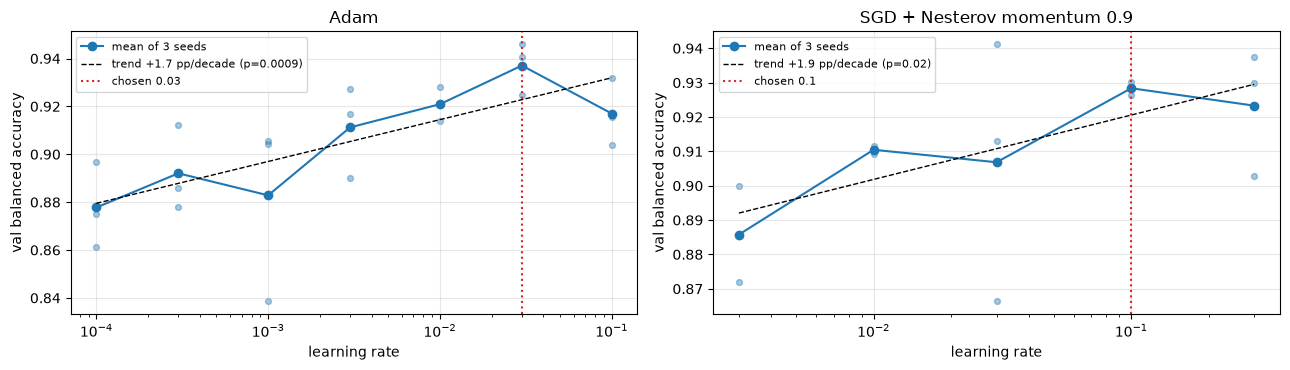

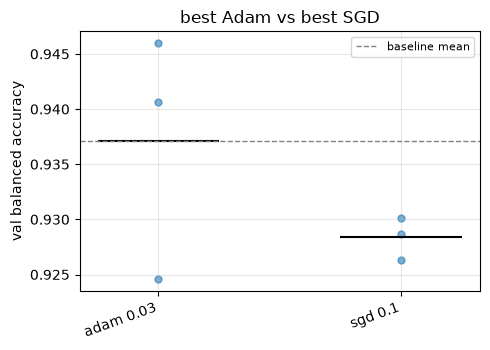

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
adam 0.03,0.9371,0.0111,3.0,0.0000,0.0505,0.9321,0.9931,0.9479,55.0,100244.0,0.5352
sgd 0.1,0.9284,0.0019,3.0,-0.0087,0.0505,0.9261,0.9927,0.9097,60.0,100244.0,0.5383


chosen optimiser: adam 0.03


In [5]:
sgd_runs, ct_sgd = lr_sweep(replace(CUR, optimizer="sgd"), [3e-3, 1e-2, 3e-2, 1e-1], "sgd")
sgd_runs = sgd_runs  # names: sgd_lr<lr>
SGD_LR = float(ct_sgd["best"])
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in ct_sgd.items() if k != "means"})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
show_sweep(adam_runs, ct_adam, "Adam", ax[0]); show_sweep(sgd_runs, ct_sgd, "SGD + Nesterov momentum 0.9", ax[1])
plt.tight_layout(); plt.show()
cur_runs = lr_runs[LR]
t_sgd = compare({f"adam {LR:g}": cur_runs, f"sgd {SGD_LR:g}": sgd_runs[SGD_LR]}, f"adam {LR:g}", "best Adam vs best SGD"); display(t_sgd)
OPT = "sgd" if pick(t_sgd, f"adam {LR:g}") == f"sgd {SGD_LR:g}" else "adam"
if OPT == "sgd":
    CUR = replace(CUR, optimizer="sgd", lr=SGD_LR); cur_runs = sgd_runs[SGD_LR]
print("chosen optimiser:", OPT, CUR.lr)

**Result.** Best Adam (0.03): 0.937. Best SGD with Nesterov momentum (0.1, from its own LR sweep): 0.928, with
lower no_tumor recall (0.910 vs 0.948).

**Decision: Adam 0.03** (highest mean).

*Other rounds.* Adam in r1 and r3 as well (r3: Adam 0.936, SGD 0.934).

## 3. Batch size

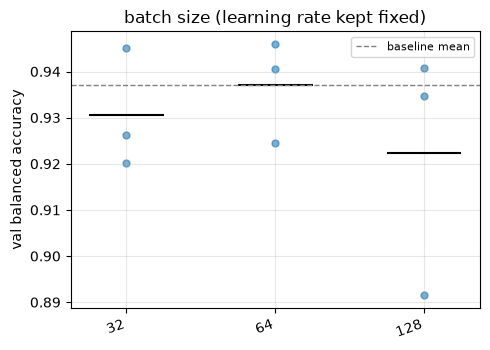

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
32,0.9305,0.0130,3.0,-0.0065,0.0505,0.9240,0.9937,0.9306,58.0000,100244.0,0.6527
64,0.9371,0.0111,3.0,0.0000,0.0505,0.9321,0.9931,0.9479,55.0000,100244.0,0.5352
128,0.9223,0.0269,3.0,-0.0148,0.0505,0.9129,0.9924,0.9375,50.6667,100244.0,0.5209


{'slope_per_decade': np.float64(-0.0137), 'slope_ci': (np.float64(-0.07124655568284119), np.float64(0.0438891528358785)), 'p_linear': np.float64(0.5917), 'p_quadratic': np.float64(0.4439), 'has_shape': False, 'best': 64, 'best_at_edge': False}
chosen batch size: 64


In [6]:
bs_runs = {str(bs): (cur_runs if bs == 64 else run_seeds(replace(CUR, name=f"{OPT}_lr{CUR.lr:g}_bs{bs}", batch_size=bs)))
           for bs in [32, 64, 128]}
t = compare(bs_runs, "64", "batch size (learning rate kept fixed)"); display(t)
ct_bs = curve_test({int(k): v for k, v in bs_runs.items()})
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in ct_bs.items() if k != "means"})
BS = int(ct_bs["best"]); CUR = replace(CUR, batch_size=BS); cur_runs = bs_runs[str(BS)]; print("chosen batch size:", BS)

**Result.** 32: 0.931, **64: 0.937**, 128: 0.922 (learning rate kept at 0.03). No trend across the sizes
(p = 0.59): the differences are seed noise.

**Decision: batch size 64** (highest mean).

*Other rounds.* This is one of the unstable choices: r1 picked 32, r3 picked 128 (32: 0.935, 64: 0.936,
128: 0.938). All within about 1.5 pp; batch size does not matter much in this range.

## 4. Learning-rate schedule

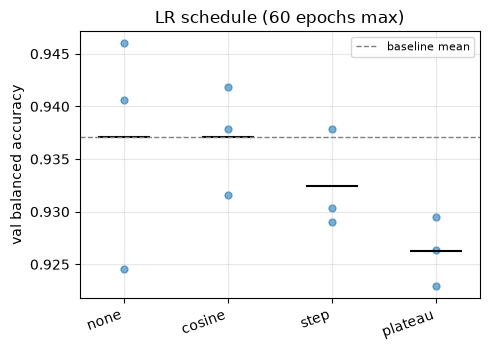

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
none,0.9371,0.0111,3.0,0.0000,0.0505,0.9321,0.9931,0.9479,55.0000,100244.0,0.5352
cosine,0.9371,0.0051,3.0,0.0000,0.0505,0.9325,0.9942,0.9444,56.6667,100244.0,0.5424
step,0.9324,0.0048,3.0,-0.0046,0.0505,0.9325,0.9935,0.9236,55.3333,100244.0,0.5424
plateau,0.9263,0.0033,3.0,-0.0108,0.0505,0.9247,0.9929,0.9063,50.6667,100244.0,0.5432


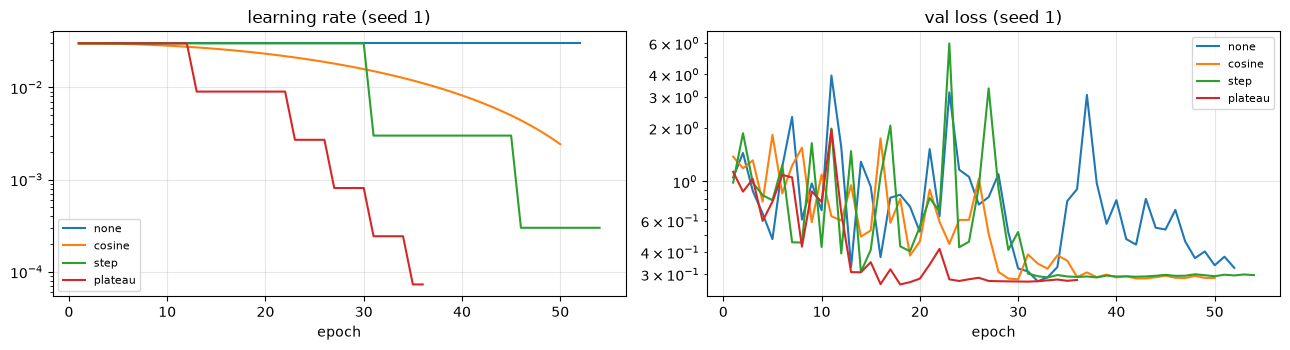

chosen schedule: none


In [7]:
tag = f"{OPT}_lr{CUR.lr:g}_bs{BS}"
sch = {"none": cur_runs, **{s: run_seeds(replace(CUR, name=f"{tag}_{s}", schedule=s)) for s in ["cosine", "step", "plateau"]}}
t = compare(sch, "none", "LR schedule (60 epochs max)"); display(t)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for k, rs in sch.items():
    h = pd.DataFrame(rs[0]["history"])
    ax[0].plot(h.epoch, h.lr, label=k); ax[1].plot(h.epoch, h.val_loss, label=k)
ax[0].set(yscale="log", title="learning rate (seed 1)", xlabel="epoch"); ax[1].set(yscale="log", title="val loss (seed 1)", xlabel="epoch")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
SCHED = pick(t, "none"); CUR = replace(CUR, schedule=SCHED); cur_runs = sch[SCHED]; print("chosen schedule:", SCHED)

**Result.** none 0.937, cosine 0.937, step 0.932, reduce-on-plateau 0.926. None and cosine tie exactly; with
equal means the first option listed (none) is kept.

**Decision: no schedule.**

*Other rounds.* No schedule in r1 and r3. In r3 (cap 200 epochs) cosine scored only 0.913: its decay is sized
to the 200-epoch cap, and early stopping usually ended the run long before the learning rate had decayed, so
the comparison at a raised cap is unfair to cosine and step.

## 5. Loss function and class imbalance

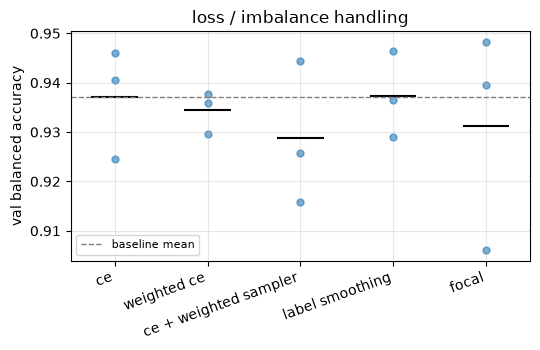

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
ce,0.9371,0.0111,3.0,0.0000,0.0505,0.9321,0.9931,0.9479,55.0000,100244.0,0.5352
weighted ce,0.9344,0.0042,3.0,-0.0027,0.0505,0.9249,0.9938,0.9549,54.6667,100244.0,0.5438
ce + weighted sampler,0.9287,0.0145,3.0,-0.0083,0.0505,0.9203,0.9901,0.9444,59.6667,100244.0,0.5438
label smoothing,0.9373,0.0088,3.0,0.0003,0.0505,0.9303,0.9957,0.9548,57.0000,100244.0,0.5537
focal,0.9313,0.0223,3.0,-0.0058,0.0505,0.9264,0.9949,0.9236,51.0000,100244.0,0.5520


mean per-class recall:


,glioma,meningioma,no_tumor,pituitary
ce,0.941,0.872,0.948,0.987
weighted ce,0.917,0.898,0.955,0.968
ce + weighted sampler,0.889,0.914,0.944,0.968
label smoothing,0.904,0.928,0.955,0.963
focal,0.910,0.910,0.924,0.981


chosen: label smoothing


In [8]:
tag = f"{OPT}_lr{CUR.lr:g}_bs{BS}_{SCHED}"
loss = {"ce": cur_runs,
        "weighted ce": run_seeds(replace(CUR, name=f"{tag}_wce", loss="weighted_ce")),
        "ce + weighted sampler": run_seeds(replace(CUR, name=f"{tag}_sampler", sampler="weighted")),
        "label smoothing": run_seeds(replace(CUR, name=f"{tag}_ls", loss="label_smoothing")),
        "focal": run_seeds(replace(CUR, name=f"{tag}_focal", loss="focal"))}
t = compare(loss, "ce", "loss / imbalance handling"); display(t)
rec = pd.DataFrame({k: pd.DataFrame([r["val"]["recall"] for r in rs]).mean() for k, rs in loss.items()}).T
print("mean per-class recall:"); display(rec.round(3))
LOSS = pick(t, "ce")
key = {"ce": {}, "weighted ce": {"loss": "weighted_ce"}, "ce + weighted sampler": {"sampler": "weighted"},
       "label smoothing": {"loss": "label_smoothing"}, "focal": {"loss": "focal"}}[LOSS]
CUR = replace(CUR, **key); print("chosen:", LOSS)

**Result.** cross-entropy 0.937, class-weighted CE 0.934, CE + weighted sampler 0.929, **label smoothing 0.937**,
focal 0.931. Label smoothing beats plain CE by 0.03 pp, which is nothing. What differs is the per-class recall:
plain CE is strongest on glioma (0.941) and weakest on meningioma (0.872); label smoothing is more even
(glioma 0.904, meningioma 0.928) and has the best tumour AUC (0.996).

**Decision: label smoothing (0.1)** (highest mean).

*Other rounds.* Another unstable choice: r1 kept plain CE (tie rule), r3 picked focal loss (0.941 vs CE 0.938,
label smoothing 0.931). The imbalance fixes (weighting, sampler) never won: with balanced accuracy as the target
and 4 classes of reasonable size, plain training already treats the small classes well enough.

## Decisions

| # | Setting | Choice | Mean val bal. acc (3 seeds) | Runner-up |
|---|---|---|---|---|
| 1 | learning rate | Adam 0.03 | 0.937 | 0.01: 0.921 |
| 2 | optimiser | Adam | 0.937 | SGD 0.1: 0.928 |
| 3 | batch size | 64 | 0.937 | 32: 0.931 |
| 4 | schedule | none | 0.937 | cosine 0.937 (tie) |
| 5 | loss | label smoothing | 0.937 | CE 0.937 |

**c6 result: 0.937** (from 0.883 for the same input at the c4 settings). Almost all of the gain comes from the
learning rate; the other four settings move the score by less than the seed noise, which is why different rounds
picked different batch sizes and losses.

**Across rounds.** r1 (tie rule): Adam 0.03, batch 32, CE, 0.934. r2 (this run): 0.937. r3 (200-epoch cap): Adam
0.03, batch 128, focal, 0.941. The learning rate is the only robust finding.

In [9]:
OPTIM = dict(optimizer=CUR.optimizer, lr=CUR.lr, batch_size=CUR.batch_size, schedule=CUR.schedule,
             loss=CUR.loss, sampler=CUR.sampler)
_ = (ARTIFACTS / "optim.json").write_text(json.dumps(OPTIM))
print(OPTIM, "-> mean val bal. acc", round(log_progress("c6 optimisation", loss[LOSS]), 4))

{'optimizer': 'adam', 'lr': 0.03, 'batch_size': 64, 'schedule': 'none', 'loss': 'label_smoothing', 'sampler': 'none'} -> mean val bal. acc 0.9373
